# Analysis of the task-substitution run

This notebook reads the results that `task_shortcutting_eval.ipynb` saved to the Hugging Face Bucket and evaluates them in depth. It needs **no GPU**: a free CPU runtime is enough.

**Requires:** the main notebook has run through **section 4 (Grading)**, so that `results/graded.csv` exists in the bucket. The analysis uses whatever has been graded so far, so it also works on a partial run.

**What it adds beyond the main notebook's summary:**

1. **Coverage and grading quality:** how many answers per mode and condition, truncation, judge vs. rule-grader agreement, and your manual judge audit.
2. **Headline metrics with confidence intervals:** accuracy per condition, shortcut rate, COR, the substitution share of errors, and recovery. Every CI is a 95% cluster bootstrap over original problems.
3. **Paired analyses:**
   - Does substitution happen even when the model knows the original?
   - What happens to substituted items under `nudge` and `contrast`?
   - Does thinking change the outcome for the same item?
4. **Deep dives:** the GSM-Plus unanswerable items, response length by outcome, silent vs. disclosed substitution, and riddles written by Qwen vs. by other models.
5. **Figures, README-ready tables and an example browser.** Outputs are saved under `analysis/` and uploaded to the bucket.

## 0 · Setup

In [5]:
HF_BUCKET = "Erenko-13/llm-task-shortcutting"
UPLOAD_ANALYSIS = True     # upload the tables and figures of this notebook to the bucket under analysis/
SEED = 0

In [6]:
import subprocess, sys

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "huggingface_hub", "tabulate"], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '-U', 'huggingface_hub', 'tabulate'], returncode=0)

In [7]:
import json
from pathlib import Path

from huggingface_hub import login, sync_bucket

LOCAL = Path("/content/artifacts")
ANALYSIS = LOCAL / "analysis"
ANALYSIS.mkdir(parents=True, exist_ok=True)

# The bucket is private until the main notebook publishes it, so log in with the same token.
try:
    from google.colab import userdata
    token = userdata.get("HF_TOKEN")
except Exception:
    token = None
if not token:
    from getpass import getpass
    token = getpass("Hugging Face token: ")
login(token=token)

sync_bucket(f"hf://buckets/{HF_BUCKET}", str(LOCAL), quiet=True)
for path in sorted(LOCAL.rglob("*")):
    if path.is_file() and "analysis" not in path.parts:
        print(f"{path.relative_to(LOCAL)}   {path.stat().st_size / 1e6:.1f} MB")

README.md   0.0 MB
analyze_results.ipynb   0.5 MB
data/eval_items.jsonl   3.7 MB
figures/accuracy_by_condition.png   0.1 MB
figures/outcome_mix_perturbed.png   0.1 MB
results/generations_no_think.jsonl   12.9 MB
results/generations_think.jsonl   84.9 MB
results/graded.csv   96.6 MB
results/judge_audit.csv   0.0 MB
results/judgments.jsonl   0.8 MB
results/summary.csv   0.0 MB
task_shortcutting_eval.ipynb   0.3 MB
upload/README.md   0.0 MB
upload/analyze_results.ipynb   0.5 MB
upload/task_shortcutting_eval.ipynb   0.3 MB


## 1 · Load

In [8]:
import numpy as np
import pandas as pd

graded_path = LOCAL / "results" / "graded.csv"
if not graded_path.exists():
    raise FileNotFoundError("results/graded.csv is not in the bucket yet: run the main notebook through section 4 first.")

items = pd.read_json(LOCAL / "data" / "eval_items.jsonl", lines=True)
ITEMS_BY_ID = {r["id"]: r for r in items.to_dict("records")}
graded = pd.read_csv(graded_path, keep_default_na=False, na_values=[""])
for col in ("truncated", "discloses_change", "mentions_familiar", "thinking_flags_change", "thinking_mentions_familiar"):
    graded[col] = graded[col].astype(str).str.lower().eq("true")
graded["final_answer"] = graded["final_answer"].fillna("")
graded["response"] = graded["response"].fillna("")

CONDITIONS = ["canonical", "perturbed", "nudge", "contrast"]
MODIFIED_CONDITIONS = CONDITIONS[1:]
ERRORS = ["shortcut", "other_wrong", "competing", "ambiguous"]
DATASETS = [d for d in ["riddles", "gsm"] if d in set(graded.dataset)]
MODES = [m for m in ["no_think", "think"] if m in set(graded["mode"])]
DATASET_NAMES = {"riddles": "Altered riddles", "gsm": "GSM-Plus"}
SUBGROUP_NAMES = {"constraint_addition": "constraint addition", "meaning_shift": "meaning shift",
                  "context_swap": "context swap", "bias_probe": "bias probe",
                  "critical_thinking": "made unanswerable", "reversing_operation": "question reversed",
                  "numerical_substitution": "numbers changed", "original": "original"}
MODE_NAMES = {"no_think": "Thinking off", "think": "Thinking on"}
rng = np.random.default_rng(SEED)

# Did the model answer the original correctly (per mode)? Used by COR and the paired analyses.
canon_ok = (graded[graded.condition == "canonical"].groupby(["mode", "id"]).label
            .agg(lambda s: s.eq("correct").mean() >= 0.5))
graded["knows_original"] = [canon_ok.get((m, c), np.nan) if cond != "canonical" else np.nan
                            for m, c, cond in zip(graded["mode"], graded.canonical_id, graded.condition)]
print(f"{len(graded)} graded responses, {len(items)} evaluation items")

7578 graded responses, 3789 evaluation items


## 2 · Coverage and grading quality
Check these before reading any metric:

- **Coverage:** every mode × condition should have the expected number of answers.
- **No answer:** `unparseable` (no final answer) and `truncated` (hit the token limit) should be small. A high share in thinking mode means `MAX_NEW_TOKENS["think"]` was too low.
- **Judge vs. rule grader:** they should mostly agree wherever the rule grader made a decision.

In [9]:
display(pd.crosstab([graded.dataset, graded["mode"]], graded.condition, margins=True))
display(pd.crosstab([graded.dataset, graded["mode"]], graded.label, normalize="index").style.format("{:.1%}"))
print("Truncated (hit the token limit), by mode:")
display(graded.groupby(["dataset", "mode"]).truncated.mean().unstack().style.format("{:.1%}"))

condition         canonical  contrast  nudge  perturbed   All
dataset mode                                                 
gsm     no_think        150       450    450        450  1500
        think           150       450    450        450  1500
riddles no_think        189       700    700        700  2289
        think           189       700    700        700  2289
All                     678      2300   2300       2300  7578

Truncated (hit the token limit), by mode:


mode,no_think,think
dataset,,
gsm,4.9%,0.2%
riddles,6.2%,1.8%


In [10]:
# Judge vs. rule grader, where the rule grader decided.
decided = graded[graded.rule_label.isin(["correct", "shortcut", "other_wrong", "competing"])]
for dataset, d in decided.groupby("dataset"):
    agree = (d.rule_label == d.label).mean()
    print(f"\n{DATASET_NAMES[dataset]}: rule grader decided {len(d)} answers, judge agrees on {agree:.1%}")
    display(pd.crosstab(d.rule_label, d.label, rownames=["rule grader"], colnames=["judge (final label)"]))

# Manual audit, if you filled in human_label in results/judge_audit.csv.
audit_path = LOCAL / "results" / "judge_audit.csv"
if audit_path.exists():
    audit = pd.read_csv(audit_path, keep_default_na=False)
    labeled = audit[audit.human_label.str.strip() != ""]
    if len(labeled):
        print(f"\nManual audit: judge agrees with you on {(labeled.label == labeled.human_label.str.strip()).mean():.0%} "
              f"of {len(labeled)} hand-labeled answers")
        display(pd.crosstab(labeled.human_label, labeled.label, rownames=["human"], colnames=["judge"]))
    else:
        print("\nManual audit: judge_audit.csv has no human labels yet. Fill in the human_label column, upload it to "
              "the bucket under results/, and re-run this cell.")


GSM-Plus: rule grader decided 2908 answers, judge agrees on 91.3%


judge (final label),correct,other_wrong,shortcut
rule grader,,,
correct,2226,5,0
other_wrong,177,361,35
shortcut,22,13,69



Altered riddles: rule grader decided 2222 answers, judge agrees on 94.5%


judge (final label),competing,correct,other_wrong,shortcut
rule grader,,,,
competing,124,62,0,13
correct,0,1442,3,0
shortcut,0,36,9,533



Manual audit: judge_audit.csv has no human labels yet. Fill in the human_label column, upload it to the bucket under results/, and re-run this cell.


## 3 · Headline metrics with confidence intervals

Every metric is computed per thinking mode × dataset × modification type. Every CI is a 95% **cluster bootstrap**: original problems are resampled with replacement 2,000 times, because items built from the same original are not independent.

| metric | calculation |
|---|---|
| `acc_<condition>` | correct / answers in that condition (`canonical`: the originals behind the group) |
| `shortcut_rate` | shortcut / answers in `perturbed` |
| `COR` | among `perturbed` items whose original was answered correctly: shortcut / items |
| `subst_share` | shortcut / errors in `perturbed` (errors = shortcut, other, competing, ambiguous) |
| `recovery_nudge`, `recovery_contrast` | accuracy in that condition − accuracy in `perturbed` |

In [11]:
def per_cluster_counts(sub):
    """Count columns per cluster (original problem) for one group's modified rows."""
    def count(cond, mask_fn):
        rows = sub[sub.condition == cond]
        return rows.groupby("cluster").label.agg(lambda s: mask_fn(s).sum())
    p = sub[sub.condition == "perturbed"]
    known = p[p.knows_original.eq(True)]
    cols = {
        "n_p": p.groupby("cluster").size(),
        "correct_p": count("perturbed", lambda s: s.eq("correct")),
        "short_p": count("perturbed", lambda s: s.eq("shortcut")),
        "err_p": count("perturbed", lambda s: s.isin(ERRORS)),
        "n_known": known.groupby("cluster").size(),
        "short_known": known.groupby("cluster").label.agg(lambda s: s.eq("shortcut").sum()),
    }
    for cond in ("nudge", "contrast"):
        cols[f"n_{cond}"] = sub[sub.condition == cond].groupby("cluster").size()
        cols[f"correct_{cond}"] = count(cond, lambda s: s.eq("correct"))
    return pd.DataFrame(cols).fillna(0)


def ratio(a, b):
    """a / b, NaN where b is 0; works on numbers and on arrays (all bootstrap samples at once)."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(b > 0, a / b, np.nan)


STATS = {
    "acc_perturbed": lambda s: ratio(s.correct_p, s.n_p),
    "acc_nudge": lambda s: ratio(s.correct_nudge, s.n_nudge),
    "acc_contrast": lambda s: ratio(s.correct_contrast, s.n_contrast),
    "shortcut_rate": lambda s: ratio(s.short_p, s.n_p),
    "COR": lambda s: ratio(s.short_known, s.n_known),
    "subst_share": lambda s: ratio(s.short_p, s.err_p),
    "recovery_nudge": lambda s: ratio(s.correct_nudge, s.n_nudge) - ratio(s.correct_p, s.n_p),
    "recovery_contrast": lambda s: ratio(s.correct_contrast, s.n_contrast) - ratio(s.correct_p, s.n_p),
}


def bootstrap(per, n=2000):
    """Resample clusters n times; returns {metric: (2.5th, 97.5th percentile)}."""
    arr = per.to_numpy(float)
    idx = rng.integers(0, len(arr), (n, len(arr)))
    sums = pd.DataFrame(arr[idx].sum(axis=1), columns=per.columns)   # one row per bootstrap sample
    out = {}
    for name, fn in STATS.items():
        vals = np.asarray(fn(sums), dtype=float)
        out[name] = np.nanpercentile(vals, [2.5, 97.5]) if np.isfinite(vals).any() else (np.nan, np.nan)
    return out


def summarize(mode_df, sub):
    per = per_cluster_counts(sub)
    totals = per.sum()
    canon = mode_df[(mode_df.condition == "canonical") & mode_df.id.isin(sub.canonical_id)]
    row = {"items": sub[sub.condition == "perturbed"].pair_id.nunique(),
           "acc_canonical": canon.label.eq("correct").mean()}
    cis = bootstrap(per)
    for name, fn in STATS.items():
        row[name] = float(fn(totals))
        lo, hi = cis[name]
        row[f"{name}_ci"] = "" if np.isnan(lo) else f"[{lo:.0%}, {hi:.0%}]"
    return row


rows = []
for mode, d in graded.groupby("mode", sort=False):
    for dataset in DATASETS:
        mod = d[(d.dataset == dataset) & (d.condition != "canonical")]
        if mod.empty:
            continue
        rows.append({"mode": mode, "dataset": dataset, "group": "ALL", **summarize(d, mod)})
        for subgroup, s in mod.groupby("subgroup"):
            rows.append({"mode": mode, "dataset": dataset, "group": SUBGROUP_NAMES.get(subgroup, subgroup),
                         **summarize(d, s)})
        if dataset == "riddles":
            for flag, s in mod.groupby(mod.qwen_generated.astype(str).str.lower().eq("true")):
                rows.append({"mode": mode, "dataset": dataset, "group": "written by Qwen" if flag else "written by others",
                             **summarize(d, s)})

summary = pd.DataFrame(rows)
summary.to_csv(ANALYSIS / "summary_with_ci.csv", index=False)
pct = [c for c in summary.columns if c in ("acc_canonical", *STATS)]
display(summary.style.format({c: "{:.0%}" for c in pct}, na_rep="–"))

,mode,dataset,group,items,acc_canonical,acc_perturbed,acc_perturbed_ci,acc_nudge,acc_nudge_ci,acc_contrast,acc_contrast_ci,shortcut_rate,shortcut_rate_ci,COR,COR_ci,subst_share,subst_share_ci,recovery_nudge,recovery_nudge_ci,recovery_contrast,recovery_contrast_ci
0,no_think,riddles,ALL,700,37%,34%,"[30%, 38%]",35%,"[31%, 39%]",38%,"[34%, 43%]",18%,"[15%, 22%]",29%,"[24%, 33%]",30%,"[25%, 35%]",1%,"[-3%, 4%]",4%,"[0%, 8%]"
1,no_think,riddles,bias probe,144,38%,32%,"[25%, 40%]",33%,"[26%, 41%]",30%,"[22%, 37%]",26%,"[19%, 33%]",39%,"[26%, 52%]",41%,"[32%, 51%]",1%,"[-7%, 10%]",-2%,"[-11%, 7%]"
2,no_think,riddles,constraint addition,236,40%,37%,"[32%, 43%]",40%,"[34%, 46%]",45%,"[39%, 52%]",17%,"[13%, 22%]",22%,"[15%, 29%]",30%,"[22%, 38%]",3%,"[-4%, 9%]",8%,"[2%, 14%]"
3,no_think,riddles,context swap,139,37%,38%,"[30%, 46%]",32%,"[24%, 39%]",40%,"[32%, 49%]",10%,"[5%, 15%]",22%,"[11%, 34%]",18%,"[10%, 27%]",-6%,"[-14%, 1%]",2%,"[-7%, 11%]"
4,no_think,riddles,meaning shift,181,38%,29%,"[23%, 36%]",32%,"[25%, 39%]",34%,"[27%, 41%]",20%,"[14%, 26%]",35%,"[25%, 48%]",30%,"[21%, 39%]",3%,"[-3%, 9%]",4%,"[-2%, 11%]"
5,no_think,riddles,written by others,561,38%,34%,"[29%, 38%]",34%,"[29%, 38%]",37%,"[33%, 42%]",19%,"[15%, 22%]",29%,"[24%, 35%]",30%,"[25%, 36%]",-0%,"[-4%, 4%]",4%,"[-1%, 8%]"
6,no_think,riddles,written by Qwen,139,38%,37%,"[28%, 46%]",40%,"[32%, 48%]",42%,"[33%, 50%]",17%,"[11%, 25%]",27%,"[16%, 40%]",29%,"[18%, 41%]",4%,"[-5%, 13%]",5%,"[-3%, 13%]"
7,no_think,gsm,ALL,450,96%,72%,"[69%, 75%]",72%,"[69%, 76%]",78%,"[74%, 82%]",5%,"[3%, 7%]",5%,"[3%, 7%]",22%,"[14%, 31%]",0%,"[-3%, 3%]",6%,"[3%, 9%]"
8,no_think,gsm,made unanswerable,150,96%,33%,"[26%, 41%]",33%,"[26%, 41%]",51%,"[43%, 59%]",13%,"[9%, 19%]",13%,"[8%, 19%]",25%,"[16%, 35%]",0%,"[-8%, 8%]",17%,"[8%, 27%]"
9,no_think,gsm,numbers changed,150,96%,89%,"[84%, 94%]",90%,"[85%, 95%]",91%,"[85%, 95%]",1%,"[0%, 3%]",1%,"[0%, 3%]",14%,"[0%, 36%]",1%,"[-2%, 3%]",1%,"[-3%, 5%]"


## 4 · Paired analyses

### 4.1 Does the model substitute even when it knows the original?
For every modified item, we check whether the model answered its **original** correctly in the same thinking mode. If substitution is driven by memory of the familiar problem, the shortcut rate should be highest when the original is known.

In [12]:
p = graded[(graded.condition == "perturbed") & graded.knows_original.notna()].copy()
p["knows_original"] = p.knows_original.map({True: "original answered correctly", False: "original answered wrong"})
table = pd.crosstab([p.dataset, p["mode"], p.knows_original], p.label, normalize="index")
display(table.reindex(columns=[c for c in ["correct", "shortcut", "other_wrong", "competing", "ambiguous", "unparseable"]
                               if c in table.columns]).style.format("{:.0%}"))

### 4.2 What happens to substituted items under `nudge` and `contrast`?
We take the items where the model gave the original's answer in `perturbed`, and look at the same item in the other two conditions:

- **fixed:** now correct, so the model could solve it.
- **still shortcut:** the substitution persists even when warned, or when shown the original.

In [13]:
wide = graded[graded.condition != "canonical"].pivot_table(
    index=["dataset", "mode", "pair_id"], columns="condition", values="label", aggfunc="first")
substituted = wide[wide.perturbed == "shortcut"]
transition = []
for (dataset, mode), g in substituted.groupby(level=["dataset", "mode"]):
    for cond in ("nudge", "contrast"):
        if cond in g:
            counts = g[cond].value_counts(normalize=True)
            transition.append({"dataset": dataset, "mode": mode, "condition": cond, "n": len(g),
                               "fixed (correct)": counts.get("correct", 0), "still shortcut": counts.get("shortcut", 0),
                               "other": 1 - counts.get("correct", 0) - counts.get("shortcut", 0)})
transition = pd.DataFrame(transition)
transition.to_csv(ANALYSIS / "recovery_of_substituted_items.csv", index=False)
display(transition.style.format({c: "{:.0%}" for c in ["fixed (correct)", "still shortcut", "other"]}))

,dataset,mode,condition,n,fixed (correct),still shortcut,other
0,gsm,no_think,nudge,22,18%,36%,45%
1,gsm,no_think,contrast,22,32%,36%,32%
2,gsm,think,nudge,14,21%,64%,14%
3,gsm,think,contrast,14,64%,29%,7%
4,riddles,no_think,nudge,129,16%,44%,40%
5,riddles,no_think,contrast,129,20%,34%,46%
6,riddles,think,nudge,188,28%,48%,24%
7,riddles,think,contrast,188,26%,45%,30%


### 4.3 Thinking on vs. off, for the same items
Only items answered in both modes are compared, on the `perturbed` condition. Rows show the thinking-off label, and columns the thinking-on label. The off-diagonal cells show whether thinking fixes substitutions or introduces them.

In [14]:
if len(MODES) == 2:
    both = graded[graded.condition == "perturbed"].pivot_table(index=["dataset", "pair_id"], columns="mode",
                                                               values="label", aggfunc="first").dropna()
    for dataset, g in both.groupby(level="dataset"):
        print(f"\n{DATASET_NAMES[dataset]}: {len(g)} items answered in both modes")
        display(pd.crosstab(g.no_think, g.think, rownames=["thinking off"], colnames=["thinking on"], margins=True))
        fixed = ((g.no_think == "shortcut") & (g.think == "correct")).sum()
        introduced = ((g.no_think == "correct") & (g.think == "shortcut")).sum()
        print(f"thinking fixes {fixed} substitutions and introduces {introduced}")
else:
    print("Only one thinking mode has been graded so far.")


GSM-Plus: 450 items answered in both modes


thinking on,correct,other_wrong,shortcut,unparseable,All
thinking off,,,,,
correct,315,8,1,0,324
other_wrong,32,43,3,1,79
shortcut,9,3,10,0,22
unparseable,17,8,0,0,25
All,373,62,14,1,450


thinking fixes 9 substitutions and introduces 1

Altered riddles: 700 items answered in both modes


thinking on,competing,correct,other_wrong,shortcut,unparseable,All
thinking off,,,,,,
competing,7,9,2,4,0,22
correct,4,179,25,31,1,240
other_wrong,7,92,111,64,4,278
shortcut,1,22,21,82,3,129
unparseable,0,8,8,7,8,31
All,19,310,167,188,16,700


thinking fixes 22 substitutions and introduces 31


## 5 · Deep dives

### 5.1 GSM-Plus "made unanswerable"
A needed number was removed, so the correct answer is "cannot be determined". Giving the **original problem's number** means the model filled in the missing fact from the familiar version. This is the clearest case of substitution.

In [15]:
ct = graded[(graded.dataset == "gsm") & (graded.subgroup == "critical_thinking")]
if len(ct):
    display(pd.crosstab([ct["mode"], ct.condition], ct.label, normalize="index").style.format("{:.0%}"))
    sample = ct[(ct.condition == "perturbed") & (ct.label == "shortcut")].head(3)
    for _, r in sample.iterrows():
        it = ITEMS_BY_ID[r.id]
        print("=" * 90, f"\n{r.id} ({r['mode']})\nMODIFIED: {it['question']}\nORIGINAL ANSWER: {it['shortcut']}"
              f"\nMODEL'S FINAL ANSWER: {r.final_answer}")

gsm-005-critical_thinking-perturbed (no_think)
MODIFIED: At Allan's house, there is twice as much corn as cannolis. Allan bought 60 more cannolis at the store and 40 fewer corns than the number of cannolis. Find the combined total of the number of corns and cannolis Allan has in the house?
ORIGINAL ANSWER: 200
MODEL'S FINAL ANSWER: 200
gsm-014-critical_thinking-perturbed (no_think)
MODIFIED: Frankie watches TV after he finishes his homework every night. On Monday and Tuesday, he watched a 1-hour episode of his favorite show each night. On Wednesday, he watched a few episodes of a 30-minute show. On Thursday, he finished homework early and watched a 1-hour episode and a 30-minute show. On Friday, he got to stay up late for the weekend, so he watched two 1-hour episodes. How many 30-minute episodes did he watch on Wednesday?
ORIGINAL ANSWER: 3
MODEL'S FINAL ANSWER: 3
gsm-033-critical_thinking-perturbed (no_think)
MODIFIED: James is in charge of running messages from the office to each te

### 5.2 Is substitution silent?
Among answers labeled `shortcut`, this is the share that **mention** a change ("modified", "different from", "assuming", "missing", …) in the visible answer, and the share whose **thinking trace** mentions a change or a familiar version. Substitution that is never mentioned is what makes it look like a confident hallucination.

In [16]:
subs = graded[graded.label.eq("shortcut") & graded.condition.isin(["perturbed", "nudge"])]
silence = subs.groupby(["dataset", "mode", "condition"]).agg(
    shortcut_answers=("id", "size"),
    disclosed_in_answer=("discloses_change", "mean"),
    noticed_in_thinking=("thinking_flags_change", "mean"),
    familiar_in_thinking=("thinking_mentions_familiar", "mean"))
display(silence.style.format({c: "{:.0%}" for c in ["disclosed_in_answer", "noticed_in_thinking", "familiar_in_thinking"]}))

### 5.3 Response length by outcome
Are shortcut answers shorter, i.e. less work? With thinking on, `n_tokens` is mostly reasoning length.

In [17]:
lengths = (graded[graded.condition == "perturbed"].groupby(["dataset", "mode", "label"]).n_tokens
           .agg(["count", "median", "mean"]).round(0))
display(lengths)

count   median     mean
dataset mode     label                               
gsm     no_think correct        324    313.0    422.0
                 other_wrong     79    820.0   1114.0
                 shortcut        22    657.0    978.0
                 unparseable     25   4096.0   4096.0
        think    correct        373   2291.0   3032.0
                 other_wrong     62   5836.0   6160.0
                 shortcut        14   5104.0   6330.0
                 unparseable      1  16384.0  16384.0
riddles no_think competing       22    588.0    795.0
                 correct        240    169.0    436.0
                 other_wrong    278    262.0    706.0
                 shortcut       129    173.0    405.0
                 unparseable     31   4096.0   4096.0
        think    competing       19   5912.0   5906.0
                 correct        310   5538.0   5685.0
                 other_wrong    167   7732.0   8013.0
                 shortcut       188   6010.0   6505.0
                 unparseable     16  16384.0  16384.0

## 6 · Figures
Saved to `analysis/` (and uploaded to the bucket).

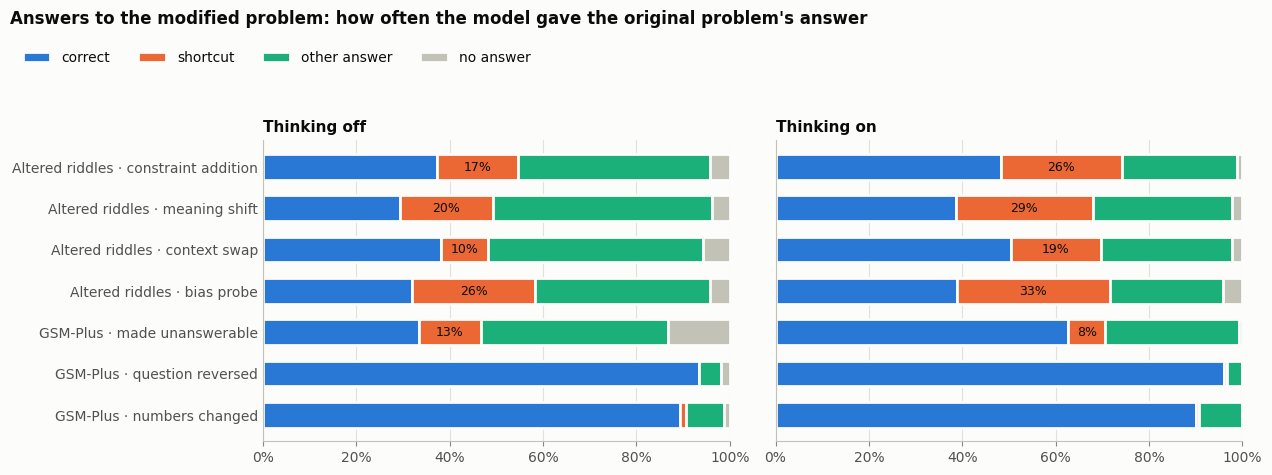

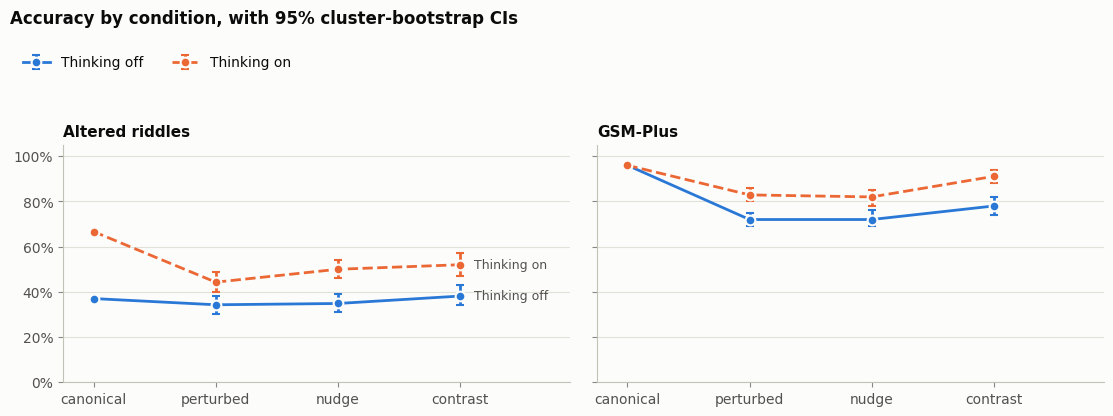

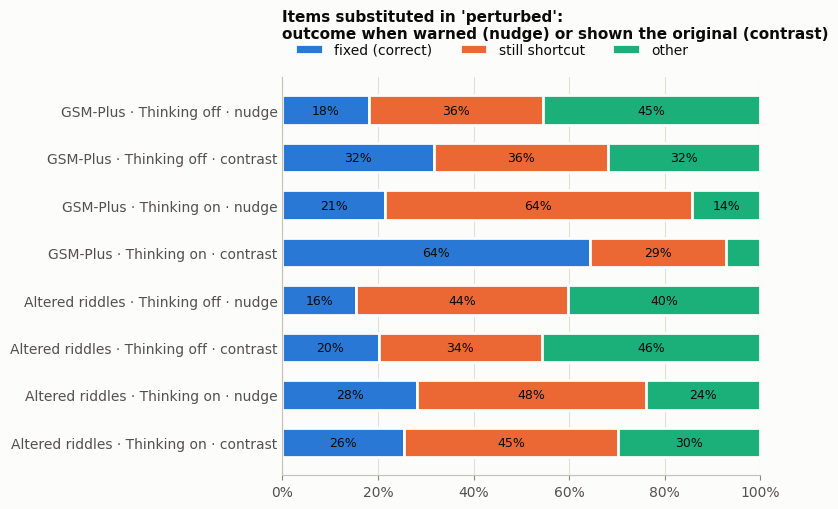

In [18]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

SURFACE, INK, INK2, MUTED, GRID, BASELINE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})
OUTCOME_COLORS = {"correct": "#2a78d6", "shortcut": "#eb6834", "other answer": "#1baf7a", "no answer": BASELINE}
MODE_STYLES = {"no_think": ("#2a78d6", "-"), "think": ("#eb6834", "--")}

# Figure A: outcome mix on the modified problem, per modification type.
pert = graded[graded.condition == "perturbed"].copy()
pert["group"] = pert.dataset.map(DATASET_NAMES) + " · " + pert.subgroup.map(SUBGROUP_NAMES)
pert["outcome"] = pert.label.map({"correct": "correct", "shortcut": "shortcut", "unparseable": "no answer",
                                  "unjudged": "no answer"}).fillna("other answer")
order = [f"{DATASET_NAMES[d]} · {SUBGROUP_NAMES[s]}" for d, s in
         [("riddles", "constraint_addition"), ("riddles", "meaning_shift"), ("riddles", "context_swap"),
          ("riddles", "bias_probe"), ("gsm", "critical_thinking"), ("gsm", "reversing_operation"),
          ("gsm", "numerical_substitution")]]
order = [g for g in order if g in set(pert.group)]
mix = pd.crosstab([pert["mode"], pert.group], pert.outcome, normalize="index").reindex(columns=list(OUTCOME_COLORS), fill_value=0)

fig, axes = plt.subplots(1, len(MODES), figsize=(6.4 * len(MODES), 4.8), sharey=True, squeeze=False)
for ax, mode in zip(axes[0], MODES):
    d = mix.loc[mode].reindex(order[::-1]).fillna(0)
    left = np.zeros(len(d))
    for outcome, color in OUTCOME_COLORS.items():
        vals = d[outcome].to_numpy()
        ax.barh(d.index, vals, left=left, height=0.62, color=color, edgecolor=SURFACE, linewidth=2, label=outcome)
        if outcome == "shortcut":
            for y, (l, v) in enumerate(zip(left, vals)):
                if v >= 0.08:
                    ax.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=9, color=INK)
        left += vals
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(MODE_NAMES[mode], loc="left")
handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=4, loc="upper left", bbox_to_anchor=(0.01, 0.92))
fig.suptitle("Answers to the modified problem: how often the model gave the original problem's answer",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.85))
fig.savefig(ANALYSIS / "outcome_mix.png", dpi=200, bbox_inches="tight")
plt.show()

# Figure B: accuracy across conditions with 95% CIs, one panel per dataset.
fig, axes = plt.subplots(1, len(DATASETS), figsize=(5.6 * len(DATASETS), 4.2), sharey=True, squeeze=False)
for i, (ax, dataset) in enumerate(zip(axes[0], DATASETS)):
    for mode in MODES:
        s = summary[(summary["mode"] == mode) & (summary.dataset == dataset) & (summary.group == "ALL")]
        if s.empty:
            continue
        s = s.iloc[0]
        y = np.array([s.acc_canonical, s.acc_perturbed, s.acc_nudge, s.acc_contrast], dtype=float)
        lo_hi = [(np.nan, np.nan)] + [tuple(float(v.strip("%")) / 100 for v in s[f"acc_{c}_ci"].strip("[]").split(", "))
                                      if s[f"acc_{c}_ci"] else (np.nan, np.nan) for c in MODIFIED_CONDITIONS]
        err = np.array([[max(y[k] - lo, 0), max(hi - y[k], 0)] if not np.isnan(lo) else [0, 0]
                        for k, (lo, hi) in enumerate(lo_hi)]).T
        color, style = MODE_STYLES[mode]
        ax.errorbar(range(4), y, yerr=err, fmt="o" + style, color=color, lw=2, ms=7, capsize=3,
                    markeredgecolor=SURFACE, markeredgewidth=1.5, label=MODE_NAMES[mode])
        if i == 0:
            ax.annotate(MODE_NAMES[mode], (3, y[-1]), xytext=(10, 0), textcoords="offset points",
                        va="center", fontsize=9, color=INK2)
    ax.set_title(DATASET_NAMES[dataset], loc="left")
    ax.set_ylim(0, 1.05)
    ax.set_xlim(-0.25, 3.9)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xticks(range(4), CONDITIONS)
    ax.grid(axis="x", visible=False)
handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=2, loc="upper left", bbox_to_anchor=(0.01, 0.9))
fig.suptitle("Accuracy by condition, with 95% cluster-bootstrap CIs", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.82))
fig.savefig(ANALYSIS / "accuracy_by_condition_ci.png", dpi=200, bbox_inches="tight")
plt.show()

# Figure C: what happens to substituted items under nudge and contrast.
if len(transition):
    t = transition.copy()
    t["row"] = t.dataset.map(DATASET_NAMES) + " · " + t["mode"].map(MODE_NAMES) + " · " + t.condition
    t = t.iloc[::-1]
    colors = {"fixed (correct)": "#2a78d6", "still shortcut": "#eb6834", "other": "#1baf7a"}
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(t) + 1.6))
    left = np.zeros(len(t))
    for col, color in colors.items():
        ax.barh(t.row, t[col], left=left, height=0.62, color=color, edgecolor=SURFACE, linewidth=2, label=col)
        for y, (l, v) in enumerate(zip(left, t[col])):
            if v >= 0.1:
                ax.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=9, color=INK)
        left += t[col].to_numpy()
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.02))
    ax.set_title("Items substituted in 'perturbed':\noutcome when warned (nudge) or shown the original (contrast)",
                 loc="left", pad=28)
    fig.tight_layout()
    fig.savefig(ANALYSIS / "recovery_of_substituted_items.png", dpi=200, bbox_inches="tight")
    plt.show()

## 7 · README-ready tables
Markdown versions of the key numbers, to paste into the README (also saved as `analysis/tables.md`).

In [19]:
def fmt(v):
    return "–" if pd.isna(v) else f"{v:.0%}"


key = summary[summary.group == "ALL"].copy()
lines = ["| mode | dataset | acc canonical | acc perturbed | shortcut rate | COR | substitution share of errors | recovery (contrast) |",
         "|---|---|---|---|---|---|---|---|"]
for _, r in key.iterrows():
    lines.append(f"| {MODE_NAMES[r['mode']]} | {DATASET_NAMES[r.dataset]} | {fmt(r.acc_canonical)} | {fmt(r.acc_perturbed)} "
                 f"{r.acc_perturbed_ci} | {fmt(r.shortcut_rate)} | {fmt(r.COR)} | {fmt(r.subst_share)} {r.subst_share_ci} "
                 f"| {fmt(r.recovery_contrast)} {r.recovery_contrast_ci} |")
by_type = summary[summary.group != "ALL"]
lines += ["", "| mode | dataset | type | items | acc perturbed | shortcut rate | substitution share of errors |",
          "|---|---|---|---|---|---|---|"]
for _, r in by_type.iterrows():
    lines.append(f"| {MODE_NAMES[r['mode']]} | {DATASET_NAMES[r.dataset]} | {r.group} | {r['items']} | "
                 f"{fmt(r.acc_perturbed)} | {fmt(r.shortcut_rate)} | {fmt(r.subst_share)} {r.subst_share_ci} |")
tables_md = "\n".join(lines)
(ANALYSIS / "tables.md").write_text(tables_md, encoding="utf-8")
print(tables_md)

| mode | dataset | acc canonical | acc perturbed | shortcut rate | COR | substitution share of errors | recovery (contrast) |
|---|---|---|---|---|---|---|---|
| Thinking off | Altered riddles | 37% | 34% [30%, 38%] | 18% | 29% | 30% [25%, 35%] | 4% [0%, 8%] |
| Thinking off | GSM-Plus | 96% | 72% [69%, 75%] | 5% | 5% | 22% [14%, 31%] | 6% [3%, 9%] |
| Thinking on | Altered riddles | 67% | 44% [40%, 49%] | 27% | 34% | 50% [44%, 56%] | 8% [4%, 11%] |
| Thinking on | GSM-Plus | 96% | 83% [80%, 86%] | 3% | 3% | 18% [10%, 28%] | 8% [5%, 11%] |

| mode | dataset | type | items | acc perturbed | shortcut rate | substitution share of errors |
|---|---|---|---|---|---|---|
| Thinking off | Altered riddles | bias probe | 144 | 32% | 26% | 41% [32%, 51%] |
| Thinking off | Altered riddles | constraint addition | 236 | 37% | 17% | 30% [22%, 38%] |
| Thinking off | Altered riddles | context swap | 139 | 38% | 10% | 18% [10%, 27%] |
| Thinking off | Altered riddles | meaning shift | 181 | 29% | 20%

## 8 · Example browser
Call `show(...)` with any filter to read real responses. These are the qualitative evidence for the write-up.

In [20]:
def show(dataset="riddles", label="shortcut", condition="perturbed", mode=None, subgroup=None, n=3, seed=SEED):
    mode = mode or MODES[0]
    sub = graded[(graded.dataset == dataset) & (graded.label == label) &
                 (graded.condition == condition) & (graded["mode"] == mode)]
    if subgroup:
        sub = sub[sub.subgroup == subgroup]
    print(f"{len(sub)} matching responses")
    for _, r in sub.sample(min(n, len(sub)), random_state=seed).iterrows():
        it = ITEMS_BY_ID[r.id]
        answer = r.response.rsplit("</think>", 1)[-1].strip()
        print("=" * 100)
        print(f"[{DATASET_NAMES[dataset]} · {SUBGROUP_NAMES.get(r.subgroup, r.subgroup)} · {MODE_NAMES[mode]}] {r.id}")
        print(f"gold: {str(it['gold'])[:200]}\nshortcut: {str(it['shortcut'])[:200]}\nfinal answer: {r.final_answer[:200]}")
        print("ORIGINAL:\n" + ITEMS_BY_ID[it["canonical_id"]]["question"])
        print("MODIFIED:\n" + it["question"])
        print("ANSWER (end):\n" + answer[-800:])


show("riddles")
show("gsm", subgroup="critical_thinking")

129 matching responses
[Altered riddles · constraint addition · Thinking off] riddle-alt_0559-perturbed
gold: Halley's Comet
shortcut: The moon
final answer: Total Solar Eclipse
ORIGINAL:
I am the hole in the night, the ever watchful eye. I return in a cycle, to enlighten the sky.
MODIFIED:
I am the hole in the night, the ever watchful eye. I return in a cycle, to enlighten the sky, yet I visit but once in a lifetime.
ANSWER (end):
This riddle describes a celestial event that occurs when the Moon passes directly between the Earth and the Sun, casting a shadow on Earth.

*   "The hole in the night" refers to the darkness created during totality.
*   "The ever watchful eye" is a poetic reference to the Moon (often associated with eyes or watching).
*   "Return in a cycle" refers to the lunar phases and the fact that eclipses happen periodically based on orbital mechanics.
*   "Visit but once in a lifetime" highlights that while eclipses occur regularly for an observer's location over tho

## 9 · Upload the analysis
Uploads `analysis/` (tables, CSVs and figures) to the bucket. The bucket stays private until the main notebook's publish cell runs.

In [21]:
if UPLOAD_ANALYSIS:
    sync_bucket(str(ANALYSIS), f"hf://buckets/{HF_BUCKET}/analysis", quiet=True)
    print("uploaded:", sorted(p.name for p in ANALYSIS.iterdir()))

uploaded: ['accuracy_by_condition_ci.png', 'outcome_mix.png', 'recovery_of_substituted_items.csv', 'recovery_of_substituted_items.png', 'report.md', 'summary_with_ci.csv', 'tables.md']


## 10 · Report (README)
Writes the full report as `README.md`: setup, data quality, results, verdicts, every finding from the sections above, and examples. It is built from the numbers computed in this notebook, so run everything above first. Re-running regenerates it.

- **Your own text:** write the answers to Q1 and Q3 in `Q1_TEXT` / `Q3_TEXT` below. They are inserted as-is.
- **Verdicts:** decided by fixed rules with stated thresholds. The rules are printed in the report.
- **Where it goes:** saved and uploaded as `analysis/report.md`. The bucket's root `README.md` is the hand-edited final report (the same file as the GitHub README), uploaded in section 11. Only with `UPLOAD_README = True` does this cell overwrite it with the generated report.

In [22]:
import re

# ---- Your own text (Markdown). Inserted into the report as-is. ----
Q1_TEXT = r"""**Task substitution: the model answers the familiar question instead of the one it was asked.**

When a prompt closely resembles a task the model has seen many times, but one detail that changes the answer is
different, the model often solves the familiar version and returns *its* answer. From the outside this looks like a
hallucination: a confident, wrong answer. But nothing is made up. It is the correct answer to a different, easier
question, namely the original one.

I kept running into this when using LLMs: answers that looked hallucinated often turned out to be a correct answer to
a more common, slightly different version of what I had asked. The model had quietly made my task easier.

**Why it is a blind spot.**

- Benchmarks score answers as right or wrong. A substituted answer counts as one more error, indistinguishable from a
  calculation mistake or a hallucination, so the failure mode itself is never measured.
- The usual fixes for hallucination (retrieval, more knowledge, calibration) do not target it. The model is not
  missing knowledge. It applies knowledge it has to the wrong question, and knowing the original makes it *more*
  likely to fail (see below).
- It is silent. The model rarely says it assumed the usual version, so a user has no signal to double-check.
- In real use, the changed detail is often the whole point: an unusual clause in a standard contract, the edge case
  in a familiar piece of code, a patient who differs from the textbook case.

**What this evaluation shows** (details in the sections below): on altered riddles with thinking on, half of all
errors are exactly the original riddle's answer, and 84% of those answers never mention that anything was changed.
The model substitutes 2.5 times as often on riddles whose original it knows. On math word problems the model mostly
recomputes correctly, but when a needed fact is deleted it often fills the gap instead of saying the problem cannot
be solved (only 33% of answers with thinking off and 63% with thinking on say so)."""

Q3_TEXT = r"""**Proposed fix: train on minimal pairs, using the familiar answer as the negative example.**

1. **Data curation: minimal-pair contrast sets.** Take task families the model has seen many times, such as classic
   riddles and puzzles, benchmark-style math word problems, textbook coding exercises, and standard documents.
   Generate variants that change one decisive detail. An LLM proposes the edit, and the new answer is verified by code
   (math, code) or by a stronger model plus spot checks (riddles). Include *unanswerable* variants made by deleting a
   needed fact, whose answer is "cannot be determined, X is missing". Each record stores the modified prompt, its
   correct answer and the original's answer. Unmodified originals stay in the mix, so the model does not learn that
   every familiar problem is a trick: accuracy on the originals (96% on GSM8K here) must not drop.

2. **Fine-tuning: preference optimization with the substituted answer as "rejected".** Task substitution comes with a
   ready-made hard negative: the original's answer given to the modified prompt. That gives DPO-style pairs directly.
   The chosen response is the correct answer to the modified problem; the rejected one is the familiar answer with
   the familiar reasoning. For unanswerable variants, chosen = "cannot be determined, because ... is missing" and
   rejected = the original problem's number. This targets exactly the error measured here, which plain fine-tuning on
   more riddles or more math would not. A few thousand pairs per task family should be enough to test this, since
   it is a narrow behaviour.

3. **Reasoning: check against the text, not just recognise the template.** In this evaluation the thinking traces
   call the problem "classic" or "well-known" in 98% of substituted riddle answers, and thinking *increased*
   substitution on riddles (from 30% to 50% of errors). So recognising the familiar version is not the problem. The
   problem is that the model never checks its answer against the actual wording afterwards. In RL with verifiable
   rewards, modified items are cheap to reward (the correct answer is known, and the familiar answer scores zero), and
   the reasoning can be shaped toward an explicit step: "this resembles X; here is what is different; does my answer
   satisfy every stated condition?" The data supports this direction. A generic "read carefully" warning changed
   accuracy by -1 to +6 pp, while showing the original next to the modified problem raised it by 4 to 8 pp, and from
   63% to 86% on unanswerable math problems with thinking on. Making the difference explicit helps; being told to be
   careful does not. The model should learn to produce that difference itself.

4. **Evaluation: report substitution next to accuracy.** Measure the shortcut rate and the substitution share of
   errors, not just accuracy. Success for the steps above means a lower shortcut rate on *held-out* task families
   (e.g. train on riddles and math, test on code and documents) while accuracy on the unmodified originals stays the
   same."""

RESULTS_TEXT = r"""1. **Riddles: substitution is the main failure.** With thinking on, Qwen3.5-4B solves 67% of the original riddles
   but only 44% of the altered ones. Half of its errors (50% [44%, 56%]) are exactly the original riddle's answer, and
   84% of these answers never mention that anything was changed. With thinking off the model knows few of the
   originals (37%), so there is less to substitute, but 30% of its errors are still the original's answer.

2. **Knowing the original causes it.** On altered riddles the model gives the original's answer 2.5 times as often
   when it solved that original correctly: 34% vs 13% with thinking on, 29% vs 12% with thinking off. This is the
   signature of substitution, not of random error. Riddles written by Qwen3.5 and by other models give the same
   rates (27% vs 27% with thinking on), so this is not an artifact of the dataset's origin.

3. **Thinking does not prevent it. On riddles it makes it worse.** Thinking raises accuracy on altered riddles (34%
   → 44%), but it raises the shortcut rate too (18% → 27%), and the substitution share of errors goes from 30% to 50%.
   On the same items, thinking fixed 22 substitutions and introduced 31. The traces call the riddle "classic" or
   "well-known" in 98% of substituted answers: the model recognises the familiar version, reasons about it at length,
   and then gives its answer.

4. **Math: mostly no substitution, except when a fact is missing.** When GSM8K problems get new numbers or a reversed
   question, accuracy stays at 89–96% and the model almost never returns the original's answer: it actually
   recomputes. When a needed fact is deleted, only 33% (thinking off) and 63% (thinking on) of answers say the
   problem cannot be solved. 13% and 8% give the original problem's number (the deleted fact was filled in from
   memory), and 40% and 29% invent some other assumption. This is a broader form of the same blind spot: the model
   turns the task into one it can answer.

5. **Warnings don't help much; showing the difference helps a little.** A generic "read carefully" warning changes
   accuracy by -1 to +6 pp. Showing the original next to the modified problem helps more (+4 to +8 pp overall; on
   unanswerable math problems from 33% to 51% with thinking off and from 63% to 86% with thinking on). But the
   familiar answer is sticky. Of the riddles substituted with thinking on, only 26% are fixed when the original is
   shown alongside, and 45% *still* give the original's answer.

6. **Grading is reasonably reliable.** The LLM judge agrees with the rule-based grader on 91% (GSM-Plus) and 94%
   (riddles) of the answers where the rules could decide. A manual audit is still to be done.

In short: the hypothesis holds clearly for riddles, where the model has a strong memorised answer to fall back on.
It does not hold for arithmetic changes, where the model recomputes. Its broader form, turning an unanswerable
problem into an answerable one, does show up in math."""
# The bucket's README.md is now the hand-edited README from the GitHub repo, uploaded with the button in section 11.
# Set this to True only if you want the auto-generated report to replace it.
UPLOAD_README = False

YES, PARTLY, NO, NA = "✅ yes", "⚠️ partly", "❌ no", "– n/a"


def pc(v):
    return "–" if v is None or pd.isna(v) else f"{v:.0%}"


def pp(v):
    return "–" if v is None or pd.isna(v) else f"{v * 100:+.0f} pp"


def tokens(v):
    return "–" if v is None or pd.isna(v) else f"{v:.0f}"


def ci_bounds(text):
    nums = re.findall(r"-?\d+", str(text))
    return (int(nums[0]) / 100, int(nums[1]) / 100) if len(nums) == 2 else (np.nan, np.nan)


def level(v, yes, partly):
    if v is None or pd.isna(v):
        return NA
    return YES if v >= yes else PARTLY if v >= partly else NO


def name_of(mode, dataset):
    return f"{MODE_NAMES[mode]} · {DATASET_NAMES[dataset]}"


# ---------------------------------------------------------------- data quality
quality = (graded.groupby(["dataset", "mode"])
           .agg(responses=("id", "size"), truncated=("truncated", "mean"),
                no_answer=("label", lambda s: s.isin(["unparseable", "unjudged"]).mean()))
           .reset_index())
quality_md = pd.DataFrame({
    "setting": [name_of(r["mode"], r["dataset"]) for _, r in quality.iterrows()],
    "responses": quality.responses,
    "hit the token limit": quality.truncated.map(pc),
    "no gradable answer": quality.no_answer.map(pc),
}).to_markdown(index=False)
coverage_md = pd.crosstab([graded.dataset.map(DATASET_NAMES), graded["mode"].map(MODE_NAMES)],
                          graded.condition).reindex(columns=CONDITIONS).reset_index().to_markdown(index=False)

agreement_lines = []
decided = graded[graded.rule_label.isin(["correct", "shortcut", "other_wrong", "competing"])]
for dataset, d in decided.groupby("dataset"):
    agreement_lines.append(f"- {DATASET_NAMES[dataset]}: where the rule-based grader made a decision ({len(d)} answers), "
                           f"the judge agrees on **{(d.rule_label == d.label).mean():.0%}**.")
audit_path = LOCAL / "results" / "judge_audit.csv"
if audit_path.exists():
    audit = pd.read_csv(audit_path, keep_default_na=False)
    labeled = audit[audit.human_label.str.strip() != ""]
    if len(labeled):
        agreement_lines.append(f"- Manual audit: the judge agrees with human labels on "
                               f"**{(labeled.label == labeled.human_label.str.strip()).mean():.0%}** of {len(labeled)} answers.")
    else:
        agreement_lines.append("- Manual audit: not done yet (`results/judge_audit.csv` has no human labels).")

# ---------------------------------------------------------------- verdicts
shortcut_rows = graded[graded.label.eq("shortcut") & graded.condition.isin(["perturbed", "nudge"])]
verdicts, overall = [], []
for _, r in summary[summary["group"] == "ALL"].iterrows():
    q = quality[(quality["dataset"] == r["dataset"]) & (quality["mode"] == r["mode"])].iloc[0]
    s = shortcut_rows[(shortcut_rows.dataset == r["dataset"]) & (shortcut_rows["mode"] == r["mode"])]
    silent = 1 - s.discloses_change.mean() if len(s) else np.nan
    drop = r["acc_canonical"] - r["acc_perturbed"]
    sub_lo, _ = ci_bounds(r["subst_share_ci"])
    rec_lo, _ = ci_bounds(r["recovery_contrast_ci"])

    v_known = level(r["acc_canonical"], 0.7, 0.4)
    v_drop = level(drop, 0.15, 0.05)
    v_sub = (NA if pd.isna(r["subst_share"]) else YES if (r["subst_share"] >= 0.5 and sub_lo >= 0.25)
             else PARTLY if r["subst_share"] >= 0.25 else NO)
    v_rec = (NA if pd.isna(r["recovery_contrast"]) else YES if rec_lo > 0
             else PARTLY if r["recovery_contrast"] > 0 else NO)
    v_sil = level(silent, 0.7, 0.4)

    if v_sub == YES and v_drop == YES and v_rec in (YES, PARTLY):
        call = "**Supported**"
    elif v_sub in (YES, PARTLY):
        call = "**Partially supported**"
    else:
        call = "**Not supported**"
    caveats = []
    if r["items"] < 50:
        caveats.append(f"only {r['items']} modified items")
    if q["truncated"] > 0.10:
        caveats.append(f"{q['truncated']:.0%} of responses hit the token limit")
    if q["no_answer"] > 0.10:
        caveats.append(f"{q['no_answer']:.0%} of responses have no gradable answer")
    if caveats:
        call += " (provisional: " + "; ".join(caveats) + ")"
    setting = name_of(r["mode"], r["dataset"])
    overall.append(f"- **{setting}:** {call}")
    verdicts += [
        {"setting": setting, "criterion": "1. Knows the familiar version",
         "evidence": f"accuracy on the originals {pc(r['acc_canonical'])}", "verdict": v_known},
        {"setting": setting, "criterion": "2. The modification hurts",
         "evidence": f"accuracy {pc(r['acc_canonical'])} → {pc(r['acc_perturbed'])} ({pp(-drop)})", "verdict": v_drop},
        {"setting": setting, "criterion": "3. Errors land on the original's answer",
         "evidence": (f"{pc(r['subst_share'])} of errors {r['subst_share_ci']}; shortcut rate {pc(r['shortcut_rate'])}; "
                      f"COR {pc(r['COR'])}"),
         "verdict": v_sub},
        {"setting": setting, "criterion": "4. Could solve it (recovery)",
         "evidence": f"contrast {pp(r['recovery_contrast'])} {r['recovery_contrast_ci']}; nudge {pp(r['recovery_nudge'])}",
         "verdict": v_rec},
        {"setting": setting, "criterion": "5. Substitution is silent",
         "evidence": f"{pc(silent)} of {len(s)} shortcut answers never mention a change", "verdict": v_sil},
    ]
verdicts_md = pd.DataFrame(verdicts).to_markdown(index=False)

# ---------------------------------------------------------------- results tables
def results_table(rows):
    return pd.DataFrame({
        "setting": [name_of(r["mode"], r["dataset"]) for _, r in rows.iterrows()],
        "type": rows["group"].values,
        "items": rows["items"].values,
        "acc canonical": rows["acc_canonical"].map(pc).values,
        "acc perturbed": [f"{pc(r['acc_perturbed'])} {r['acc_perturbed_ci']}" for _, r in rows.iterrows()],
        "acc nudge": rows["acc_nudge"].map(pc).values,
        "acc contrast": rows["acc_contrast"].map(pc).values,
        "shortcut rate": rows["shortcut_rate"].map(pc).values,
        "COR": rows["COR"].map(pc).values,
        "substitution share of errors": [f"{pc(r['subst_share'])} {r['subst_share_ci']}" for _, r in rows.iterrows()],
    }).to_markdown(index=False)


SPLITS = ["ALL", "written by Qwen", "written by others"]
headline_md = results_table(summary[summary["group"] == "ALL"])
types_md = results_table(summary[~summary["group"].isin(SPLITS)])

# ---------------------------------------------------------------- findings
findings = {}

lines = []
p41 = graded[(graded.condition == "perturbed") & graded.knows_original.notna()]
for (dataset, mode), g in p41.groupby(["dataset", "mode"]):
    known, unknown = g[g.knows_original.eq(True)], g[g.knows_original.eq(False)]
    lines.append(f"- {name_of(mode, dataset)}: shortcut rate "
                 f"**{pc(known.label.eq('shortcut').mean() if len(known) else np.nan)}** when the model answered the "
                 f"original correctly (n={len(known)}), vs "
                 f"{pc(unknown.label.eq('shortcut').mean() if len(unknown) else np.nan)} when it did not (n={len(unknown)}).")
findings["Substitution vs. knowing the original"] = lines or ["- No items."]

lines = []
if "transition" in globals() and len(transition):
    for _, t in transition.iterrows():
        lines.append(f"- {name_of(t['mode'], t['dataset'])}, `{t['condition']}`: of {t['n']} items substituted in "
                     f"`perturbed`, **{t['fixed (correct)']:.0%} fixed**, {t['still shortcut']:.0%} still gave the "
                     f"original's answer, {t['other']:.0%} other.")
findings["What happens to substituted items when warned or shown the original"] = lines or ["- No substituted items."]

lines = []
if len(MODES) == 2:
    both = graded[graded.condition == "perturbed"].pivot_table(index=["dataset", "pair_id"], columns="mode",
                                                               values="label", aggfunc="first").dropna()
    for dataset, g in both.groupby(level="dataset"):
        fixed = ((g["no_think"] == "shortcut") & (g["think"] == "correct")).sum()
        introduced = ((g["no_think"] == "correct") & (g["think"] == "shortcut")).sum()
        lines.append(f"- {DATASET_NAMES[dataset]} ({len(g)} items answered in both modes): accuracy "
                     f"{pc(g['no_think'].eq('correct').mean())} with thinking off vs "
                     f"{pc(g['think'].eq('correct').mean())} with thinking on. Thinking fixed {fixed} substitutions and "
                     f"introduced {introduced}; {pc(g['think'].eq('unparseable').mean())} of thinking answers never finished.")
findings["Thinking on vs. off (same items)"] = lines or ["- Only one thinking mode was graded."]

lines = []
ct = graded[(graded.dataset == "gsm") & (graded.subgroup == "critical_thinking") & (graded.condition == "perturbed")]
for mode, g in ct.groupby("mode"):
    lines.append(f"- {MODE_NAMES[mode]} ({len(g)} items): {pc(g.label.eq('correct').mean())} said it cannot be "
                 f"determined (correct), **{pc(g.label.eq('shortcut').mean())} gave the original problem's number** "
                 f"(filled in the missing fact), {pc(g.label.isin(['other_wrong', 'competing', 'ambiguous']).mean())} "
                 f"gave another number, {pc(g.label.isin(['unparseable', 'unjudged']).mean())} gave no answer.")
findings["GSM-Plus 'made unanswerable'"] = lines or ["- No items of this type were graded."]

lines = []
for (dataset, mode), g in shortcut_rows.groupby(["dataset", "mode"]):
    lines.append(f"- {name_of(mode, dataset)} ({len(g)} shortcut answers): {pc(g.discloses_change.mean())} mention a "
                 f"change in the answer; the thinking trace mentions a change in {pc(g.thinking_flags_change.mean())} "
                 f"and a familiar version in {pc(g.thinking_mentions_familiar.mean())}.")
findings["Is substitution silent?"] = lines or ["- No shortcut answers."]

lines = []
med = graded[graded.condition == "perturbed"].groupby(["dataset", "mode", "label"]).n_tokens.median()
for (dataset, mode), g in med.groupby(level=["dataset", "mode"]):
    g = g.droplevel([0, 1])
    lines.append(f"- {name_of(mode, dataset)}: median length {tokens(g.get('shortcut'))} tokens for shortcut answers vs "
                 f"{tokens(g.get('correct'))} for correct ones.")
findings["Response length"] = lines or ["- No items."]

lines = []
for mode in MODES:
    rows = summary[(summary["mode"] == mode) & summary["group"].isin(SPLITS[1:])]
    for _, r in rows.iterrows():
        lines.append(f"- {MODE_NAMES[mode]}, riddles {r['group']} ({r['items']} items): accuracy "
                     f"{pc(r['acc_perturbed'])}, shortcut rate {pc(r['shortcut_rate'])}.")
findings["Riddles written by Qwen vs. by other models"] = lines or ["- No riddles graded."]

by_type = summary[~summary["group"].isin(SPLITS)].dropna(subset=["shortcut_rate"])
if len(by_type):
    top = by_type.sort_values("shortcut_rate", ascending=False).iloc[0]
    findings["Modification types"] = [
        f"- Highest shortcut rate: **{DATASET_NAMES[top['dataset']]} · {top['group']}** ({MODE_NAMES[top['mode']]}): "
        f"{pc(top['shortcut_rate'])} of {top['items']} items. Full breakdown in the table above."]

findings_md = "\n\n".join(f"**{title}**\n\n" + "\n".join(lines) for title, lines in findings.items())

# ---------------------------------------------------------------- examples
examples = []
for dataset in DATASETS:
    pool = graded[(graded.dataset == dataset) & (graded.condition == "perturbed") & (graded.label == "shortcut")]
    for _, r in pool.sample(min(2, len(pool)), random_state=SEED).iterrows():
        it = ITEMS_BY_ID[r["id"]]
        orig = ITEMS_BY_ID[it["canonical_id"]]
        examples.append(
            f"**{DATASET_NAMES[dataset]} · {SUBGROUP_NAMES.get(r['subgroup'], r['subgroup'])} · {MODE_NAMES[r['mode']]}**\n\n"
            f"- Original: {orig['question'][:600]} → *{orig['gold']}*\n"
            f"- Modified: {it['question'][:600]} → *{str(it['gold'])[:200]}*\n"
            f"- Model's final answer: **{r['final_answer'][:200]}** (the original's answer)")
examples_md = "\n\n".join(examples) or "_No shortcut answers to show._"

figure_files = [("outcome_mix.png", "Answers to the modified problem, by modification type"),
                ("accuracy_by_condition_ci.png", "Accuracy by condition with 95% CIs"),
                ("recovery_of_substituted_items.png", "Substituted items under nudge and contrast")]
figures_md = "\n\n".join(f"![{title}](analysis/{name})" for name, title in figure_files if (ANALYSIS / name).exists())

# ---------------------------------------------------------------- assemble
report = f"""# Task substitution in Qwen3.5-4B

**Hypothesis.** When a prompt looks like a familiar task but differs in one key detail, a language model often
solves the familiar, easier task instead. The result looks like a hallucination, but it is actually a correct answer to
a different question: the original one.

## Overall verdict

{chr(10).join(overall)}

## What the results show

{RESULTS_TEXT}

## Q1 · The blind spot

{Q1_TEXT}

## Setup

- **Model under test:** [`Qwen/Qwen3.5-4B`](https://huggingface.co/Qwen/Qwen3.5-4B), evaluated with thinking off and on.
- **Judge:** [`Qwen/Qwen3.5-9B`](https://huggingface.co/Qwen/Qwen3.5-9B) labels each final answer `correct`, `shortcut`
  (= the original problem's answer), other, or no answer. A rule-based grader cross-checks it.
- **Data:** [`marcodsn/altered-riddles`](https://huggingface.co/datasets/marcodsn/altered-riddles) (altered versions of
  well-known riddles) and [`qintongli/GSM-Plus`](https://huggingface.co/datasets/qintongli/GSM-Plus) (GSM8K problems
  with a fact removed, the question reversed, or the numbers changed).
- **Conditions:** each modified item is asked as `perturbed` (no warning), `nudge` (with a "read carefully" warning)
  and `contrast` (shown next to the original); each original is asked once as `canonical`.
- **Confidence intervals:** 95% cluster bootstrap over original problems (2,000 resamples).
- **Code:** `task_shortcutting_eval.ipynb` (generation, judging) and `analyze_results.ipynb` (this report).

## Data quality

{coverage_md}

{quality_md}

{chr(10).join(agreement_lines)}

## Results

{headline_md}

**By modification type**

{types_md}

{figures_md}

## Verdicts

Each criterion is decided by a fixed rule:

1. **Knows the familiar version:** canonical accuracy ≥ 70% (yes), ≥ 40% (partly).
2. **The modification hurts:** accuracy drop from canonical to perturbed ≥ 15 pp (yes), ≥ 5 pp (partly).
3. **Errors land on the original's answer:** substitution share of errors ≥ 50% with CI lower bound ≥ 25% (yes), ≥ 25% (partly).
4. **Could solve it:** contrast accuracy − perturbed accuracy has a CI above 0 (yes), or is positive with a CI that includes 0 (partly).
5. **Substitution is silent:** ≥ 70% of shortcut answers never mention a change (yes), ≥ 40% (partly).

**Overall:** *supported* when 2 and 3 are yes and 4 is at least partly; *partially supported* when 3 is at least
partly; otherwise *not supported*. A verdict is marked *provisional* when there are fewer than 50 modified items, or
more than 10% of responses hit the token limit or have no gradable answer.

{verdicts_md}

## Findings

{findings_md}

## Examples of substitution

{examples_md}

## Q3 · Path forward

{Q3_TEXT}

## Limitations

- GSM8K is very likely in the model's training data. That is part of what is tested (reliance on memorized
  solutions), but it limits how far the results generalize.
- Some altered riddles were generated by Qwen3.5 models; they are reported separately above.
- The judge belongs to the same model family as the model under test. The rule-based cross-check and the manual audit
  are there to catch systematic judge errors.
- "Silent", "mentions a change" and "familiar version" use keyword matching, so they are approximate. The change
  keywords include "assume", which appears in almost every long thinking trace, so "the thinking trace mentions a
  change" is inflated; the familiar-version keywords ("classic", "well-known", ...) are more specific.
- One sample per prompt.

## Files

| path | content |
|---|---|
| `data/eval_items.jsonl` | every prompt with `gold` and `shortcut` answers |
| `results/generations_<mode>.jsonl` | raw model responses, including thinking traces |
| `results/judgments.jsonl`, `results/graded.csv` | judge outputs and final labels |
| `results/judge_audit.csv` | judgments for manual checking |
| `analysis/` | summary with CIs, recovery table, figures, this report |
| `task_shortcutting_eval.ipynb`, `analyze_results.ipynb` | the notebooks that produced everything above (run in Colab) |

Data licenses: altered-riddles Apache-2.0; GSM-Plus CC-BY-SA-4.0 (items derived from it are redistributed under the same license).
"""

(ANALYSIS / "report.md").write_text(report, encoding="utf-8")
(LOCAL / "README.md").write_text(report, encoding="utf-8")
if UPLOAD_README:
    from huggingface_hub import batch_bucket_files
    sync_bucket(str(ANALYSIS), f"hf://buckets/{HF_BUCKET}/analysis", quiet=True)
    batch_bucket_files(HF_BUCKET, add=[(str(LOCAL / "README.md"), "README.md")])
    print(f"README uploaded: https://huggingface.co/buckets/{HF_BUCKET}")

from IPython.display import Markdown
display(Markdown(report))

# Task substitution in Qwen3.5-4B

**Hypothesis.** When a prompt looks like a familiar task but differs in one key detail, a language model often
solves the familiar, easier task instead. The result looks like a hallucination, but it is actually a correct answer to
a different question: the original one.

## Overall verdict

- **Thinking off · Altered riddles:** **Partially supported**
- **Thinking off · GSM-Plus:** **Not supported**
- **Thinking on · Altered riddles:** **Supported**
- **Thinking on · GSM-Plus:** **Not supported**

## What the results show

1. **Riddles: substitution is the main failure.** With thinking on, Qwen3.5-4B solves 67% of the original riddles
   but only 44% of the altered ones. Half of its errors (50% [44%, 56%]) are exactly the original riddle's answer, and
   84% of these answers never mention that anything was changed. With thinking off the model knows few of the
   originals (37%), so there is less to substitute, but 30% of its errors are still the original's answer.

2. **Knowing the original causes it.** On altered riddles the model gives the original's answer 2.5 times as often
   when it solved that original correctly: 34% vs 13% with thinking on, 29% vs 12% with thinking off. This is the
   signature of substitution, not of random error. Riddles written by Qwen3.5 and by other models give the same
   rates (27% vs 27% with thinking on), so this is not an artifact of the dataset's origin.

3. **Thinking does not prevent it. On riddles it makes it worse.** Thinking raises accuracy on altered riddles (34%
   → 44%), but it raises the shortcut rate too (18% → 27%), and the substitution share of errors goes from 30% to 50%.
   On the same items, thinking fixed 22 substitutions and introduced 31. The traces call the riddle "classic" or
   "well-known" in 98% of substituted answers: the model recognises the familiar version, reasons about it at length,
   and then gives its answer.

4. **Math: mostly no substitution, except when a fact is missing.** When GSM8K problems get new numbers or a reversed
   question, accuracy stays at 89–96% and the model almost never returns the original's answer: it actually
   recomputes. When a needed fact is deleted, only 33% (thinking off) and 63% (thinking on) of answers say the
   problem cannot be solved. 13% and 8% give the original problem's number (the deleted fact was filled in from
   memory), and 40% and 29% invent some other assumption. This is a broader form of the same blind spot: the model
   turns the task into one it can answer.

5. **Warnings don't help much; showing the difference helps a little.** A generic "read carefully" warning changes
   accuracy by -1 to +6 pp. Showing the original next to the modified problem helps more (+4 to +8 pp overall; on
   unanswerable math problems from 33% to 51% with thinking off and from 63% to 86% with thinking on). But the
   familiar answer is sticky. Of the riddles substituted with thinking on, only 26% are fixed when the original is
   shown alongside, and 45% *still* give the original's answer.

6. **Grading is reasonably reliable.** The LLM judge agrees with the rule-based grader on 91% (GSM-Plus) and 94%
   (riddles) of the answers where the rules could decide. A manual audit is still to be done.

In short: the hypothesis holds clearly for riddles, where the model has a strong memorised answer to fall back on.
It does not hold for arithmetic changes, where the model recomputes. Its broader form, turning an unanswerable
problem into an answerable one, does show up in math.

## Q1 · The blind spot

**Task substitution: the model answers the familiar question instead of the one it was asked.**

When a prompt closely resembles a task the model has seen many times, but one detail that changes the answer is
different, the model often solves the familiar version and returns *its* answer. From the outside this looks like a
hallucination: a confident, wrong answer. But nothing is made up. It is the correct answer to a different, easier
question, namely the original one.

I kept running into this when using LLMs: answers that looked hallucinated often turned out to be a correct answer to
a more common, slightly different version of what I had asked. The model had quietly made my task easier.

**Why it is a blind spot.**

- Benchmarks score answers as right or wrong. A substituted answer counts as one more error, indistinguishable from a
  calculation mistake or a hallucination, so the failure mode itself is never measured.
- The usual fixes for hallucination (retrieval, more knowledge, calibration) do not target it. The model is not
  missing knowledge. It applies knowledge it has to the wrong question, and knowing the original makes it *more*
  likely to fail (see below).
- It is silent. The model rarely says it assumed the usual version, so a user has no signal to double-check.
- In real use, the changed detail is often the whole point: an unusual clause in a standard contract, the edge case
  in a familiar piece of code, a patient who differs from the textbook case.

**What this evaluation shows** (details in the sections below): on altered riddles with thinking on, half of all
errors are exactly the original riddle's answer, and 84% of those answers never mention that anything was changed.
The model substitutes 2.5 times as often on riddles whose original it knows. On math word problems the model mostly
recomputes correctly, but when a needed fact is deleted it often fills the gap instead of saying the problem cannot
be solved (only 33% of answers with thinking off and 63% with thinking on say so).

## Setup

- **Model under test:** [`Qwen/Qwen3.5-4B`](https://huggingface.co/Qwen/Qwen3.5-4B), evaluated with thinking off and on.
- **Judge:** [`Qwen/Qwen3.5-9B`](https://huggingface.co/Qwen/Qwen3.5-9B) labels each final answer `correct`, `shortcut`
  (= the original problem's answer), other, or no answer. A rule-based grader cross-checks it.
- **Data:** [`marcodsn/altered-riddles`](https://huggingface.co/datasets/marcodsn/altered-riddles) (altered versions of
  well-known riddles) and [`qintongli/GSM-Plus`](https://huggingface.co/datasets/qintongli/GSM-Plus) (GSM8K problems
  with a fact removed, the question reversed, or the numbers changed).
- **Conditions:** each modified item is asked as `perturbed` (no warning), `nudge` (with a "read carefully" warning)
  and `contrast` (shown next to the original); each original is asked once as `canonical`.
- **Confidence intervals:** 95% cluster bootstrap over original problems (2,000 resamples).
- **Code:** `task_shortcutting_eval.ipynb` (generation, judging) and `analyze_results.ipynb` (this report).

## Data quality

| dataset         | mode         |   canonical |   perturbed |   nudge |   contrast |
|:----------------|:-------------|------------:|------------:|--------:|-----------:|
| Altered riddles | Thinking off |         189 |         700 |     700 |        700 |
| Altered riddles | Thinking on  |         189 |         700 |     700 |        700 |
| GSM-Plus        | Thinking off |         150 |         450 |     450 |        450 |
| GSM-Plus        | Thinking on  |         150 |         450 |     450 |        450 |

| setting                        |   responses | hit the token limit   | no gradable answer   |
|:-------------------------------|------------:|:----------------------|:---------------------|
| Thinking off · GSM-Plus        |        1500 | 5%                    | 5%                   |
| Thinking on · GSM-Plus         |        1500 | 0%                    | 0%                   |
| Thinking off · Altered riddles |        2289 | 6%                    | 6%                   |
| Thinking on · Altered riddles  |        2289 | 2%                    | 2%                   |

- GSM-Plus: where the rule-based grader made a decision (2908 answers), the judge agrees on **91%**.
- Altered riddles: where the rule-based grader made a decision (2222 answers), the judge agrees on **94%**.
- Manual audit: not done yet (`results/judge_audit.csv` has no human labels).

## Results

| setting                        | type   |   items | acc canonical   | acc perturbed   | acc nudge   | acc contrast   | shortcut rate   | COR   | substitution share of errors   |
|:-------------------------------|:-------|--------:|:----------------|:----------------|:------------|:---------------|:----------------|:------|:-------------------------------|
| Thinking off · Altered riddles | ALL    |     700 | 37%             | 34% [30%, 38%]  | 35%         | 38%            | 18%             | 29%   | 30% [25%, 35%]                 |
| Thinking off · GSM-Plus        | ALL    |     450 | 96%             | 72% [69%, 75%]  | 72%         | 78%            | 5%              | 5%    | 22% [14%, 31%]                 |
| Thinking on · Altered riddles  | ALL    |     700 | 67%             | 44% [40%, 49%]  | 50%         | 52%            | 27%             | 34%   | 50% [44%, 56%]                 |
| Thinking on · GSM-Plus         | ALL    |     450 | 96%             | 83% [80%, 86%]  | 82%         | 91%            | 3%              | 3%    | 18% [10%, 28%]                 |

**By modification type**

| setting                        | type                |   items | acc canonical   | acc perturbed   | acc nudge   | acc contrast   | shortcut rate   | COR   | substitution share of errors   |
|:-------------------------------|:--------------------|--------:|:----------------|:----------------|:------------|:---------------|:----------------|:------|:-------------------------------|
| Thinking off · Altered riddles | bias probe          |     144 | 38%             | 32% [25%, 40%]  | 33%         | 30%            | 26%             | 39%   | 41% [32%, 51%]                 |
| Thinking off · Altered riddles | constraint addition |     236 | 40%             | 37% [32%, 43%]  | 40%         | 45%            | 17%             | 22%   | 30% [22%, 38%]                 |
| Thinking off · Altered riddles | context swap        |     139 | 37%             | 38% [30%, 46%]  | 32%         | 40%            | 10%             | 22%   | 18% [10%, 27%]                 |
| Thinking off · Altered riddles | meaning shift       |     181 | 38%             | 29% [23%, 36%]  | 32%         | 34%            | 20%             | 35%   | 30% [21%, 39%]                 |
| Thinking off · GSM-Plus        | made unanswerable   |     150 | 96%             | 33% [26%, 41%]  | 33%         | 51%            | 13%             | 13%   | 25% [16%, 35%]                 |
| Thinking off · GSM-Plus        | numbers changed     |     150 | 96%             | 89% [84%, 94%]  | 90%         | 91%            | 1%              | 1%    | 14% [0%, 36%]                  |
| Thinking off · GSM-Plus        | question reversed   |     150 | 96%             | 93% [89%, 97%]  | 93%         | 93%            | 0%              | 0%    | 0% [0%, 0%]                    |
| Thinking on · Altered riddles  | bias probe          |     144 | 66%             | 39% [32%, 47%]  | 49%         | 47%            | 33%             | 40%   | 57% [46%, 68%]                 |
| Thinking on · Altered riddles  | constraint addition |     236 | 68%             | 48% [42%, 55%]  | 55%         | 59%            | 26%             | 34%   | 51% [42%, 60%]                 |
| Thinking on · Altered riddles  | context swap        |     139 | 64%             | 50% [42%, 58%]  | 55%         | 56%            | 19%             | 26%   | 41% [29%, 52%]                 |
| Thinking on · Altered riddles  | meaning shift       |     181 | 69%             | 39% [31%, 47%]  | 41%         | 44%            | 29%             | 34%   | 50% [40%, 59%]                 |
| Thinking on · GSM-Plus         | made unanswerable   |     150 | 96%             | 63% [55%, 71%]  | 61%         | 86%            | 8%              | 8%    | 22% [12%, 33%]                 |
| Thinking on · GSM-Plus         | numbers changed     |     150 | 96%             | 90% [85%, 95%]  | 90%         | 90%            | 1%              | 1%    | 7% [0%, 21%]                   |
| Thinking on · GSM-Plus         | question reversed   |     150 | 96%             | 96% [93%, 99%]  | 95%         | 97%            | 1%              | 1%    | 17% [0%, 50%]                  |

![Answers to the modified problem, by modification type](analysis/outcome_mix.png)

![Accuracy by condition with 95% CIs](analysis/accuracy_by_condition_ci.png)

![Substituted items under nudge and contrast](analysis/recovery_of_substituted_items.png)

## Verdicts

Each criterion is decided by a fixed rule:

1. **Knows the familiar version:** canonical accuracy ≥ 70% (yes), ≥ 40% (partly).
2. **The modification hurts:** accuracy drop from canonical to perturbed ≥ 15 pp (yes), ≥ 5 pp (partly).
3. **Errors land on the original's answer:** substitution share of errors ≥ 50% with CI lower bound ≥ 25% (yes), ≥ 25% (partly).
4. **Could solve it:** contrast accuracy − perturbed accuracy has a CI above 0 (yes), or is positive with a CI that includes 0 (partly).
5. **Substitution is silent:** ≥ 70% of shortcut answers never mention a change (yes), ≥ 40% (partly).

**Overall:** *supported* when 2 and 3 are yes and 4 is at least partly; *partially supported* when 3 is at least
partly; otherwise *not supported*. A verdict is marked *provisional* when there are fewer than 50 modified items, or
more than 10% of responses hit the token limit or have no gradable answer.

| setting                        | criterion                               | evidence                                             | verdict   |
|:-------------------------------|:----------------------------------------|:-----------------------------------------------------|:----------|
| Thinking off · Altered riddles | 1. Knows the familiar version           | accuracy on the originals 37%                        | ❌ no     |
| Thinking off · Altered riddles | 2. The modification hurts               | accuracy 37% → 34% (-3 pp)                           | ❌ no     |
| Thinking off · Altered riddles | 3. Errors land on the original's answer | 30% of errors [25%, 35%]; shortcut rate 18%; COR 29% | ⚠️ partly |
| Thinking off · Altered riddles | 4. Could solve it (recovery)            | contrast +4 pp [0%, 8%]; nudge +1 pp                 | ⚠️ partly |
| Thinking off · Altered riddles | 5. Substitution is silent               | 67% of 249 shortcut answers never mention a change   | ⚠️ partly |
| Thinking off · GSM-Plus        | 1. Knows the familiar version           | accuracy on the originals 96%                        | ✅ yes    |
| Thinking off · GSM-Plus        | 2. The modification hurts               | accuracy 96% → 72% (-24 pp)                          | ✅ yes    |
| Thinking off · GSM-Plus        | 3. Errors land on the original's answer | 22% of errors [14%, 31%]; shortcut rate 5%; COR 5%   | ❌ no     |
| Thinking off · GSM-Plus        | 4. Could solve it (recovery)            | contrast +6 pp [3%, 9%]; nudge +0 pp                 | ✅ yes    |
| Thinking off · GSM-Plus        | 5. Substitution is silent               | 33% of 36 shortcut answers never mention a change    | ❌ no     |
| Thinking on · Altered riddles  | 1. Knows the familiar version           | accuracy on the originals 67%                        | ⚠️ partly |
| Thinking on · Altered riddles  | 2. The modification hurts               | accuracy 67% → 44% (-22 pp)                          | ✅ yes    |
| Thinking on · Altered riddles  | 3. Errors land on the original's answer | 50% of errors [44%, 56%]; shortcut rate 27%; COR 34% | ✅ yes    |
| Thinking on · Altered riddles  | 4. Could solve it (recovery)            | contrast +8 pp [4%, 11%]; nudge +6 pp                | ✅ yes    |
| Thinking on · Altered riddles  | 5. Substitution is silent               | 84% of 318 shortcut answers never mention a change   | ✅ yes    |
| Thinking on · GSM-Plus         | 1. Knows the familiar version           | accuracy on the originals 96%                        | ✅ yes    |
| Thinking on · GSM-Plus         | 2. The modification hurts               | accuracy 96% → 83% (-13 pp)                          | ⚠️ partly |
| Thinking on · GSM-Plus         | 3. Errors land on the original's answer | 18% of errors [10%, 28%]; shortcut rate 3%; COR 3%   | ❌ no     |
| Thinking on · GSM-Plus         | 4. Could solve it (recovery)            | contrast +8 pp [5%, 11%]; nudge -1 pp                | ✅ yes    |
| Thinking on · GSM-Plus         | 5. Substitution is silent               | 55% of 29 shortcut answers never mention a change    | ⚠️ partly |

## Findings

**Substitution vs. knowing the original**

- Thinking off · GSM-Plus: shortcut rate **5%** when the model answered the original correctly (n=432), vs 6% when it did not (n=18).
- Thinking on · GSM-Plus: shortcut rate **3%** when the model answered the original correctly (n=432), vs 6% when it did not (n=18).
- Thinking off · Altered riddles: shortcut rate **29%** when the model answered the original correctly (n=265), vs 12% when it did not (n=435).
- Thinking on · Altered riddles: shortcut rate **34%** when the model answered the original correctly (n=470), vs 13% when it did not (n=230).

**What happens to substituted items when warned or shown the original**

- Thinking off · GSM-Plus, `nudge`: of 22 items substituted in `perturbed`, **18% fixed**, 36% still gave the original's answer, 45% other.
- Thinking off · GSM-Plus, `contrast`: of 22 items substituted in `perturbed`, **32% fixed**, 36% still gave the original's answer, 32% other.
- Thinking on · GSM-Plus, `nudge`: of 14 items substituted in `perturbed`, **21% fixed**, 64% still gave the original's answer, 14% other.
- Thinking on · GSM-Plus, `contrast`: of 14 items substituted in `perturbed`, **64% fixed**, 29% still gave the original's answer, 7% other.
- Thinking off · Altered riddles, `nudge`: of 129 items substituted in `perturbed`, **16% fixed**, 44% still gave the original's answer, 40% other.
- Thinking off · Altered riddles, `contrast`: of 129 items substituted in `perturbed`, **20% fixed**, 34% still gave the original's answer, 46% other.
- Thinking on · Altered riddles, `nudge`: of 188 items substituted in `perturbed`, **28% fixed**, 48% still gave the original's answer, 24% other.
- Thinking on · Altered riddles, `contrast`: of 188 items substituted in `perturbed`, **26% fixed**, 45% still gave the original's answer, 30% other.

**Thinking on vs. off (same items)**

- GSM-Plus (450 items answered in both modes): accuracy 72% with thinking off vs 83% with thinking on. Thinking fixed 9 substitutions and introduced 1; 0% of thinking answers never finished.
- Altered riddles (700 items answered in both modes): accuracy 34% with thinking off vs 44% with thinking on. Thinking fixed 22 substitutions and introduced 31; 2% of thinking answers never finished.

**GSM-Plus 'made unanswerable'**

- Thinking off (150 items): 33% said it cannot be determined (correct), **13% gave the original problem's number** (filled in the missing fact), 40% gave another number, 13% gave no answer.
- Thinking on (150 items): 63% said it cannot be determined (correct), **8% gave the original problem's number** (filled in the missing fact), 29% gave another number, 1% gave no answer.

**Is substitution silent?**

- Thinking off · GSM-Plus (36 shortcut answers): 67% mention a change in the answer; the thinking trace mentions a change in 0% and a familiar version in 0%.
- Thinking on · GSM-Plus (29 shortcut answers): 45% mention a change in the answer; the thinking trace mentions a change in 100% and a familiar version in 79%.
- Thinking off · Altered riddles (249 shortcut answers): 33% mention a change in the answer; the thinking trace mentions a change in 0% and a familiar version in 0%.
- Thinking on · Altered riddles (318 shortcut answers): 16% mention a change in the answer; the thinking trace mentions a change in 97% and a familiar version in 98%.

**Response length**

- Thinking off · GSM-Plus: median length 657 tokens for shortcut answers vs 313 for correct ones.
- Thinking on · GSM-Plus: median length 5104 tokens for shortcut answers vs 2291 for correct ones.
- Thinking off · Altered riddles: median length 173 tokens for shortcut answers vs 169 for correct ones.
- Thinking on · Altered riddles: median length 6010 tokens for shortcut answers vs 5538 for correct ones.

**Riddles written by Qwen vs. by other models**

- Thinking off, riddles written by others (561 items): accuracy 34%, shortcut rate 19%.
- Thinking off, riddles written by Qwen (139 items): accuracy 37%, shortcut rate 17%.
- Thinking on, riddles written by others (561 items): accuracy 44%, shortcut rate 27%.
- Thinking on, riddles written by Qwen (139 items): accuracy 44%, shortcut rate 27%.

**Modification types**

- Highest shortcut rate: **Altered riddles · bias probe** (Thinking on): 33% of 144 items. Full breakdown in the table above.

## Examples of substitution

**Altered riddles · meaning shift · Thinking on**

- Original: I open wide and tight I shut, Sharp am I and paper-cut fingers too, so do take care, I'm good and bad, so best beware. → *Scissors*
- Modified: I open wide and tight I shut, Sharp am I and bite fingers too, so do take care, I'm good and bad, so best beware. → *A mouth*
- Model's final answer: **A Knife** (the original's answer)

**Altered riddles · meaning shift · Thinking on**

- Original: I am the hole in the night, the ever watchful eye. I return in a cycle, to enlighten the sky. → *The moon*
- Modified: I am the hole in the night, the ever watchful ear. I return in a cycle, to listen to the sky. → *A radio telescope*
- Model's final answer: **The Moon** (the original's answer)

**GSM-Plus · made unanswerable · Thinking on**

- Original: The combined age of Peter, Paul and Jean is 100 years old. Find the age of Peter knowing that Paul is 10 years older than John and that Peter’s age is equal to the sum of Paul and John's age. → *50*
- Modified: The combined age of Peter, Paul and Jean is 100 years old. Find the age of Peter knowing that Peter’s age is equal to the sum of Paul and John's age. → *None: the problem is missing information needed to answer it, so it cannot be determined.*
- Model's final answer: **50** (the original's answer)

**GSM-Plus · made unanswerable · Thinking off**

- Original: John likes to have a glass of water with breakfast, lunch and dinner.  Finally, he has one before he goes to bed as well.  John does this every weekday, but on the weekends he likes to relax and have a soda with dinner instead.  How many glasses of water does John drink in a week? → *26*
- Modified: John likes to have a glass of water with breakfast, lunch and dinner.  Finally, he has some before he goes to bed as well.  John does this every weekday, but on the weekends he likes to relax and have a soda with dinner instead.  How many glasses of water does John drink in a week? → *None: the problem is missing information needed to answer it, so it cannot be determined.*
- Model's final answer: **26** (the original's answer)

## Q3 · Path forward

**Proposed fix: train on minimal pairs, using the familiar answer as the negative example.**

1. **Data curation: minimal-pair contrast sets.** Take task families the model has seen many times, such as classic
   riddles and puzzles, benchmark-style math word problems, textbook coding exercises, and standard documents.
   Generate variants that change one decisive detail. An LLM proposes the edit, and the new answer is verified by code
   (math, code) or by a stronger model plus spot checks (riddles). Include *unanswerable* variants made by deleting a
   needed fact, whose answer is "cannot be determined, X is missing". Each record stores the modified prompt, its
   correct answer and the original's answer. Unmodified originals stay in the mix, so the model does not learn that
   every familiar problem is a trick: accuracy on the originals (96% on GSM8K here) must not drop.

2. **Fine-tuning: preference optimization with the substituted answer as "rejected".** Task substitution comes with a
   ready-made hard negative: the original's answer given to the modified prompt. That gives DPO-style pairs directly.
   The chosen response is the correct answer to the modified problem; the rejected one is the familiar answer with
   the familiar reasoning. For unanswerable variants, chosen = "cannot be determined, because ... is missing" and
   rejected = the original problem's number. This targets exactly the error measured here, which plain fine-tuning on
   more riddles or more math would not. A few thousand pairs per task family should be enough to test this, since
   it is a narrow behaviour.

3. **Reasoning: check against the text, not just recognise the template.** In this evaluation the thinking traces
   call the problem "classic" or "well-known" in 98% of substituted riddle answers, and thinking *increased*
   substitution on riddles (from 30% to 50% of errors). So recognising the familiar version is not the problem. The
   problem is that the model never checks its answer against the actual wording afterwards. In RL with verifiable
   rewards, modified items are cheap to reward (the correct answer is known, and the familiar answer scores zero), and
   the reasoning can be shaped toward an explicit step: "this resembles X; here is what is different; does my answer
   satisfy every stated condition?" The data supports this direction. A generic "read carefully" warning changed
   accuracy by -1 to +6 pp, while showing the original next to the modified problem raised it by 4 to 8 pp, and from
   63% to 86% on unanswerable math problems with thinking on. Making the difference explicit helps; being told to be
   careful does not. The model should learn to produce that difference itself.

4. **Evaluation: report substitution next to accuracy.** Measure the shortcut rate and the substitution share of
   errors, not just accuracy. Success for the steps above means a lower shortcut rate on *held-out* task families
   (e.g. train on riddles and math, test on code and documents) while accuracy on the unmodified originals stays the
   same.

## Limitations

- GSM8K is very likely in the model's training data. That is part of what is tested (reliance on memorized
  solutions), but it limits how far the results generalize.
- Some altered riddles were generated by Qwen3.5 models; they are reported separately above.
- The judge belongs to the same model family as the model under test. The rule-based cross-check and the manual audit
  are there to catch systematic judge errors.
- "Silent", "mentions a change" and "familiar version" use keyword matching, so they are approximate. The change
  keywords include "assume", which appears in almost every long thinking trace, so "the thinking trace mentions a
  change" is inflated; the familiar-version keywords ("classic", "well-known", ...) are more specific.
- One sample per prompt.

## Files

| path | content |
|---|---|
| `data/eval_items.jsonl` | every prompt with `gold` and `shortcut` answers |
| `results/generations_<mode>.jsonl` | raw model responses, including thinking traces |
| `results/judgments.jsonl`, `results/graded.csv` | judge outputs and final labels |
| `results/judge_audit.csv` | judgments for manual checking |
| `analysis/` | summary with CIs, recovery table, figures, this report |
| `task_shortcutting_eval.ipynb`, `analyze_results.ipynb` | the notebooks that produced everything above (run in Colab) |

Data licenses: altered-riddles Apache-2.0; GSM-Plus CC-BY-SA-4.0 (items derived from it are redistributed under the same license).


## 11 · Upload the notebooks and the README
The Colab kernel can't see files on your PC, so this cell shows an upload button. **Save the files first** (Ctrl+S), then click the button and pick `README.md`, `task_shortcutting_eval.ipynb` and `analyze_results.ipynb` from the project folder (you can select all three at once). They are uploaded to the bucket root, so the bucket page shows the same README as GitHub. Picking a file again replaces its bucket copy.

In [23]:
# The Colab kernel cannot read files on your PC, so the files are sent through an upload button.
# Save them first (Ctrl+S), then pick them with the button; they are uploaded to the bucket root.
import ipywidgets as widgets
from huggingface_hub import batch_bucket_files

FILES = ["README.md", "task_shortcutting_eval.ipynb", "analyze_results.ipynb"]
picker = widgets.FileUpload(accept=".ipynb,.md", multiple=True, description="Pick files")
status = widgets.Output()


def picked_files(value):
    # ipywidgets 8 gives a tuple of dicts with name/content; ipywidgets 7 gives a dict keyed by file name.
    if isinstance(value, dict):
        return [(name, bytes(f["content"])) for name, f in value.items()]
    return [(f["name"], bytes(f["content"])) for f in value]


def upload_files(change):
    with status:
        status.clear_output()
        files = [(name, content) for name, content in picked_files(change["new"]) if name in FILES]
        if not files:
            print(f"Pick {', '.join(FILES)}.")
            return
        folder = LOCAL / "upload"
        folder.mkdir(parents=True, exist_ok=True)
        for name, content in files:
            if name.endswith(".ipynb"):
                json.loads(content)  # refuse anything that is not a valid notebook file
            (folder / name).write_bytes(content)
        batch_bucket_files(HF_BUCKET, add=[(str(folder / name), name) for name, _ in files])
        print("uploaded:", ", ".join(f"{name} ({len(content) / 1e3:.0f} kB)" for name, content in files))
        missing = sorted(set(FILES) - {name for name, _ in files})
        if missing:
            print("not picked:", ", ".join(missing))
        print(f"https://huggingface.co/buckets/{HF_BUCKET}")


picker.observe(upload_files, names="value")
display(widgets.VBox([picker, status]))